In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from pathlib import Path

Shape: (303, 14)
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


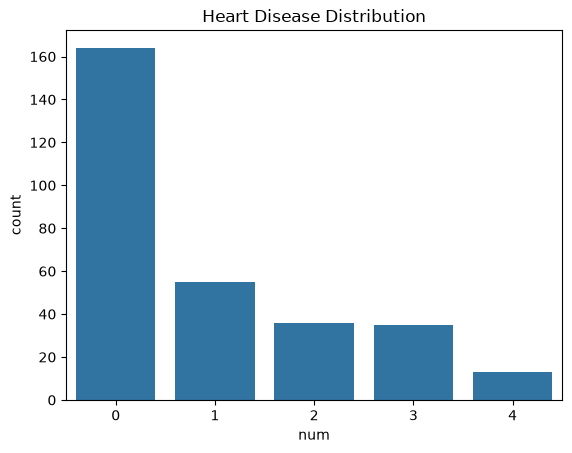

In [2]:
# Fetch dataset
heart_disease = fetch_ucirepo(id=45)

# Features and target
X = heart_disease.data.features
y = heart_disease.data.targets

# Combine into one dataframe
df = pd.concat([X, y], axis=1)

# Preview
df.head()
print("Shape:", df.shape)
df.info()
df.describe().T

sns.countplot(x='num', data=df)
plt.title("Heart Disease Distribution")
plt.show()

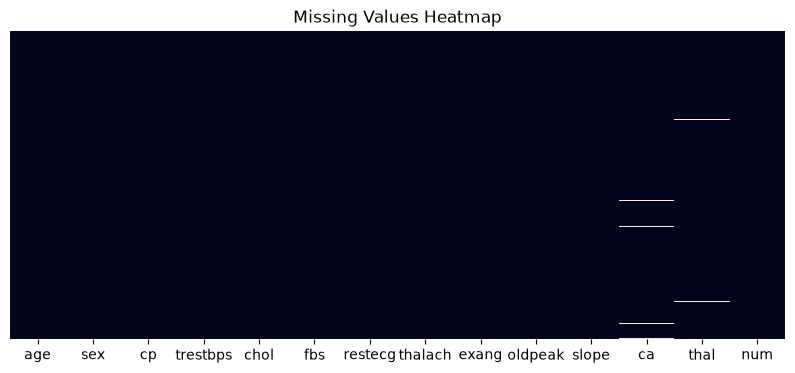

                ca  thal
Missing Values   4     2


 target
0    164
1    139
Name: count, dtype: int64
target
0    54.13
1    45.87
Name: count, dtype: float64


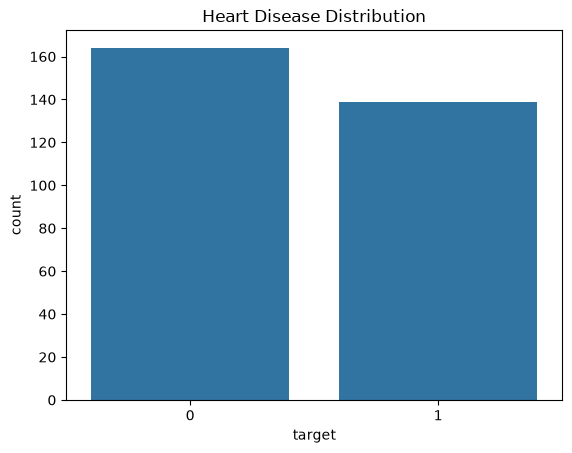

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    float64
 12  thal      303 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [ ]:
plt.figure(figsize=(10,4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title("Missing Values Heatmap")
plt.show()

missing_values = (
    df.isnull()
      .sum()
      .loc[lambda x: x > 0]
      .to_frame(name="Missing Values")
      .T
)
print(missing_values)

df["ca"] = df["ca"].fillna(df["ca"].median())
df["thal"] = df["thal"].fillna(df["thal"].mode()[0])

df["target"] = (df["num"] > 0).astype(int)
df["target"].value_counts()
target_counts = df["target"].value_counts()

# Remove original multiclass target
df = df.drop("num", axis=1)

Path("../data/processed").mkdir(parents=True, exist_ok=True)

df.to_csv("../data/processed/heart_clean.csv", index=False)

# Save processed data
df.to_csv("../data/processed/heart_clean.csv", index=False)

print("\n\n", target_counts)
print(round(target_counts / len(df) * 100, 2))

sns.countplot(x="target", data=df)
plt.title("Heart Disease Distribution")
plt.show()

df.info()
df.describe().T

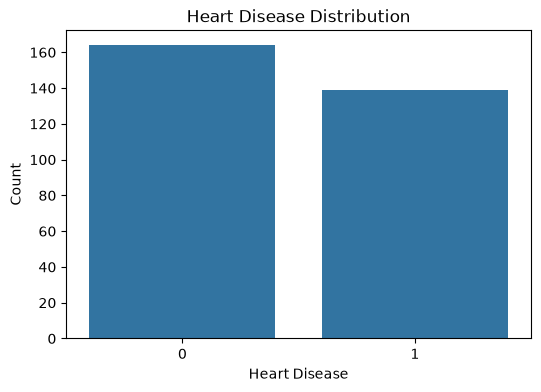

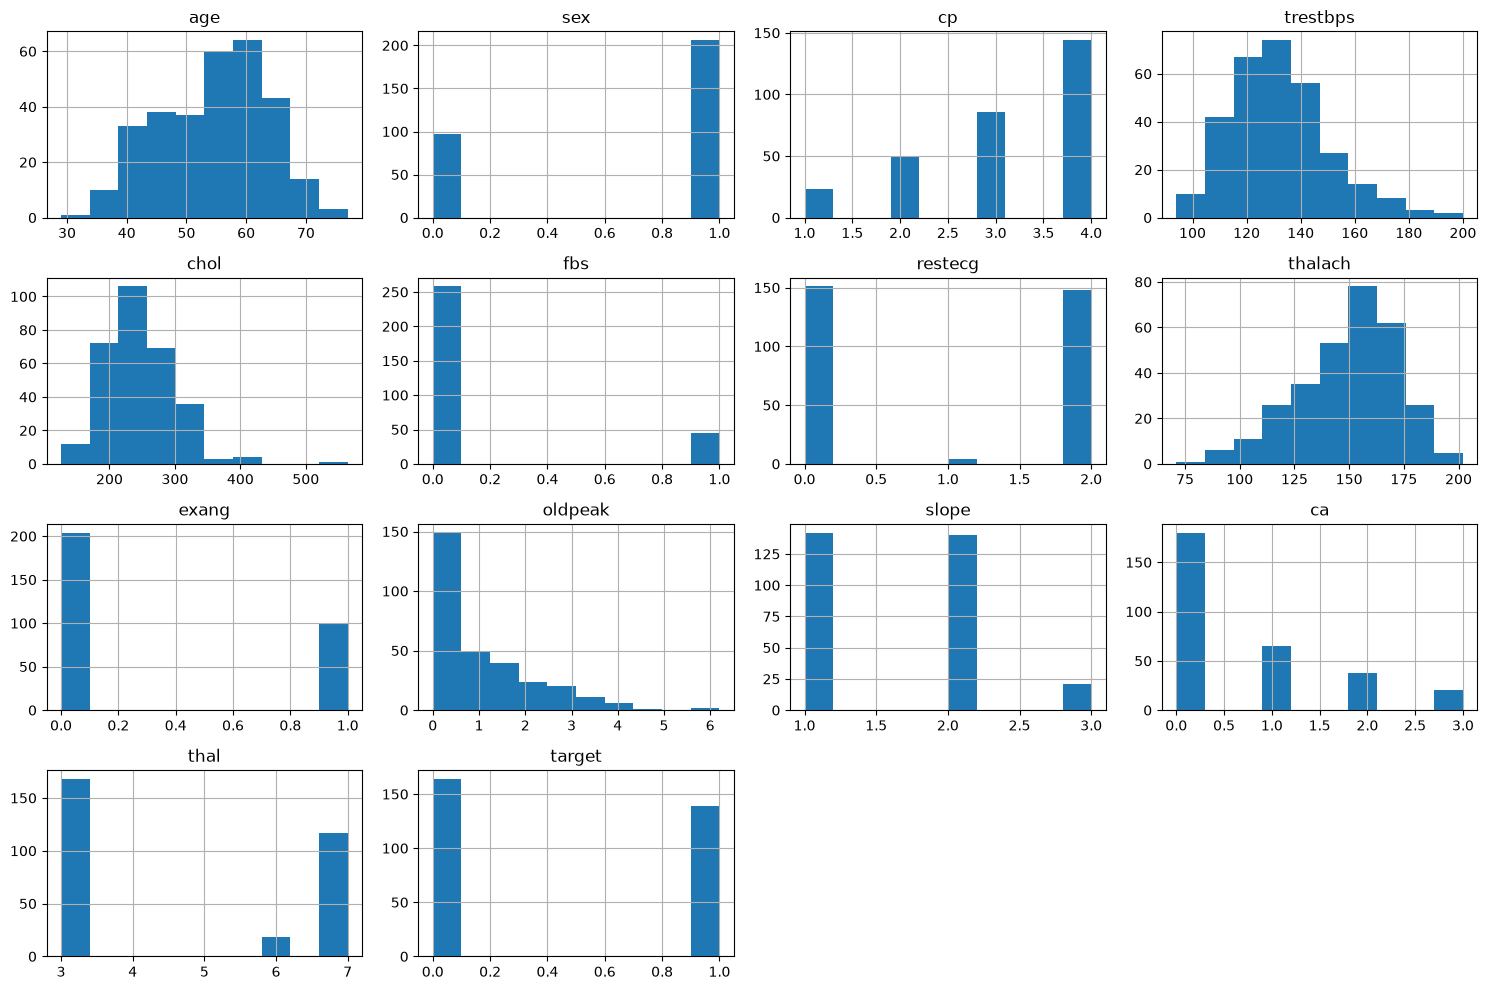

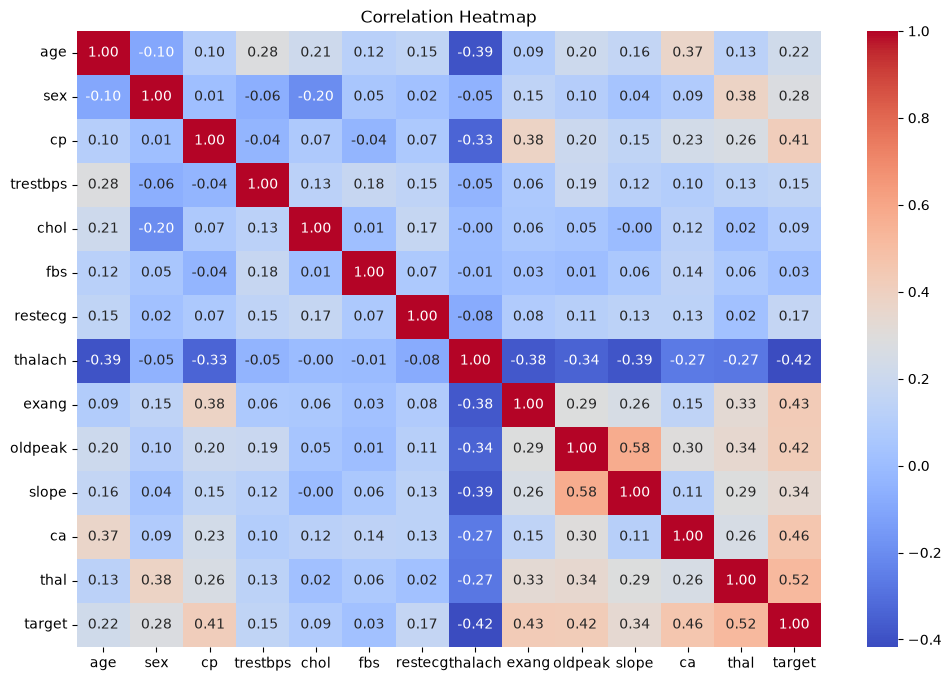

In [4]:
plt.figure(figsize=(6,4))
sns.countplot(x="target", data=df)
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Count")
plt.show()

df.hist(figsize=(15,10))
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

EDA Conclusions

The dataset contains 303 patient records with 13 clinical attributes and a binary target variable.\
Missing values were identified in the 'ca' and 'thal' features and were successfully imputed.\
The target distribution is reasonably balanced, with approximately 54% negative cases and 46% positive cases.

The strongest predictors of heart disease are:\
thal (0.522)\
ca (0.460)\
exang (0.432)\
oldpeak (0.425)\
cp (0.414)

thalach (-0.417) shows the strongest negative correlation with the target variable.

Features such as cholesterol and fasting blood sugar exhibit weak linear relationships with heart disease occurrence.\
The dataset is suitable for binary classification tasks and can be effectively modeled using algorithms such as Logistic Regression and Random Forest.